# WikiText-103 Translation Results (Selected 1000)

Analysis of the results of the EN->ES translation pipeline run on the 1,000 articles
selected from the WikiText-103 train.raw corpus.

## Contents
1. Executive summary
2. Pipeline and models
3. Volume and coverage
4. Quality (evaluation scores)
5. Problems and failures
6. Execution times
7. Costs
8. Conclusions and recommendations

In [1]:
import json
from pathlib import Path
from collections import Counter
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 5)})

PIPE_FILE = Path("../output/wikitext/wikitext-103-raw.wiki.train.selected_1000_pipeline_260620_235838.json")
ARTS_FILE = Path("../output/wikitext/wikitext-103-raw.wiki.train.selected_1000_260620_235838.json")
LOG_FILE = Path("../output/wikitext/translation_260618_015112.log")

with open(PIPE_FILE, encoding="utf-8") as f:
    pipe_data = json.load(f)
with open(ARTS_FILE, encoding="utf-8") as f:
    arts_data = json.load(f)

pipeline = pipe_data["pipeline"]
summary = pipe_data["summary"]
articles = arts_data["payload"][0]["data"]

print(f"Pipeline file: {PIPE_FILE.name}")
print(f"Articles file: {ARTS_FILE.name}")
print(f"Generated: {pipe_data['generated_at']}")
print(f"Articles: {len(pipeline):,}")

Pipeline file: wikitext-103-raw.wiki.train.selected_1000_pipeline_260620_235838.json
Articles file: wikitext-103-raw.wiki.train.selected_1000_260620_235838.json
Generated: 2026-06-20
Articles: 1,000


## 1. Executive Summary

In [2]:
# Compute the key metrics
n_total = len(pipeline)
n_with_spanish = sum(1 for a in articles if a.get("spanish", {}).get("text", "").strip())
n_review_ok = sum(1 for p in pipeline if p.get("review") is not None)
n_eval_ok = sum(1 for p in pipeline if p.get("evaluation") is not None)
n_3_cands = sum(1 for p in pipeline if len(p.get("candidates", [])) == 3)
n_2_cands = sum(1 for p in pipeline if len(p.get("candidates", [])) == 2)

scores_all = [p["evaluation"]["overall_score"] for p in pipeline if p.get("evaluation")]
avg_score = sum(scores_all) / len(scores_all) if scores_all else 0

total_cost = summary["total_cost_usd"]["total"]
total_tokens = summary["total_tokens"]["total_tokens"]

print("=" * 65)
print("EXECUTIVE SUMMARY — WikiText-103 Translation Pipeline")
print("=" * 65)
print(f"Articles processed:     {n_total:>6,}")
print(f"Translations completed: {n_with_spanish:>6,}  ({n_with_spanish/n_total*100:.1f}%)")
print(f"Reviews completed:      {n_review_ok:>6,}  ({n_review_ok/n_total*100:.1f}%)")
print(f"Evaluations completed:  {n_eval_ok:>6,}  ({n_eval_ok/n_total*100:.1f}%)")
print(f"With 3 translators:     {n_3_cands:>6,}  ({n_3_cands/n_total*100:.1f}%)")
print(f"With 2 translators:     {n_2_cands:>6,}  ({n_2_cands/n_total*100:.1f}%)")
print(f"Mean score (overall):   {avg_score:>9.1f} / 100")
print(f"Total tokens:           {total_tokens:>10,}")
print(f"Total cost:             ${total_cost:>9.2f} USD")
print(f"Mean cost/article:      ${total_cost/n_total:>9.4f} USD")
print("=" * 65)

EXECUTIVE SUMMARY — WikiText-103 Translation Pipeline
Articles processed:      1,000
Translations completed:  1,000  (100.0%)
Reviews completed:         993  (99.3%)
Evaluations completed:     995  (99.5%)
With 3 translators:        981  (98.1%)
With 2 translators:         19  (1.9%)
Mean score (overall):        95.9 / 100
Total tokens:           70,917,901
Total cost:             $   104.54 USD
Mean cost/article:      $   0.1045 USD


## 2. Pipeline and Models

The pipeline has 3 stages + metadata:
- **Stage 1 (3 translators):** each article is translated by 3 independent models
- **Stage 2 (reviewer):** a stronger model critiques the candidates and writes the final version by consensus
- **Stage 3 (evaluator):** scores the final translation with metrics + programmatic checks
- **Metadata:** generates the title, keywords, summary and classification

In [3]:
# Models used
translator_models = Counter()
for p in pipeline:
    for c in p.get("candidates", []):
        translator_models[c.get("model", "?")] += 1

reviewer_models = Counter()
for p in pipeline:
    rev = p.get("review")
    if rev:
        reviewer_models[rev.get("model", "?")] += 1

eval_models = Counter()
for p in pipeline:
    ev = p.get("evaluation")
    if ev:
        eval_models[ev.get("model", "?")] += 1

print("PIPELINE MODELS")
print("=" * 65)
print("\nStage 1 — Translators (candidates):")
for m, c in translator_models.most_common():
    short = m.split(":")[-1]
    provider = m.split(":")[0] if ":" in m else "?"
    pct = c / n_total * 100
    print(f"  {short:<45} ({provider:<8}) {c:>5} arts ({pct:.1f}%)")

print(f"\nStage 2 — Reviewer:")
for m, c in reviewer_models.most_common():
    print(f"  {m}: {c} reviews ({c/n_total*100:.1f}%)")
print(f"  No review: {n_total - n_review_ok} ({(n_total - n_review_ok)/n_total*100:.1f}%)")

print(f"\nStage 3 — Evaluator:")
for m, c in eval_models.most_common():
    print(f"  {m}: {c} evaluations ({c/n_total*100:.1f}%)")
print(f"  No evaluation: {n_total - n_eval_ok} ({(n_total - n_eval_ok)/n_total*100:.1f}%)")

PIPELINE MODELS

Stage 1 — Translators (candidates):
  dataset-frontierscience-gpt41mini             (azure   )  1000 arts (100.0%)
  9b                                            (ollama  )  1000 arts (100.0%)
  dataset-frontierscience-mistral-large         (foundry )   981 arts (98.1%)

Stage 2 — Reviewer:
  azure:dataset-frontierscience-gpt41: 993 reviews (99.3%)
  No review: 7 (0.7%)

Stage 3 — Evaluator:
  azure:dataset-frontierscience-gpt41mini: 995 evaluations (99.5%)
  No evaluation: 5 (0.5%)


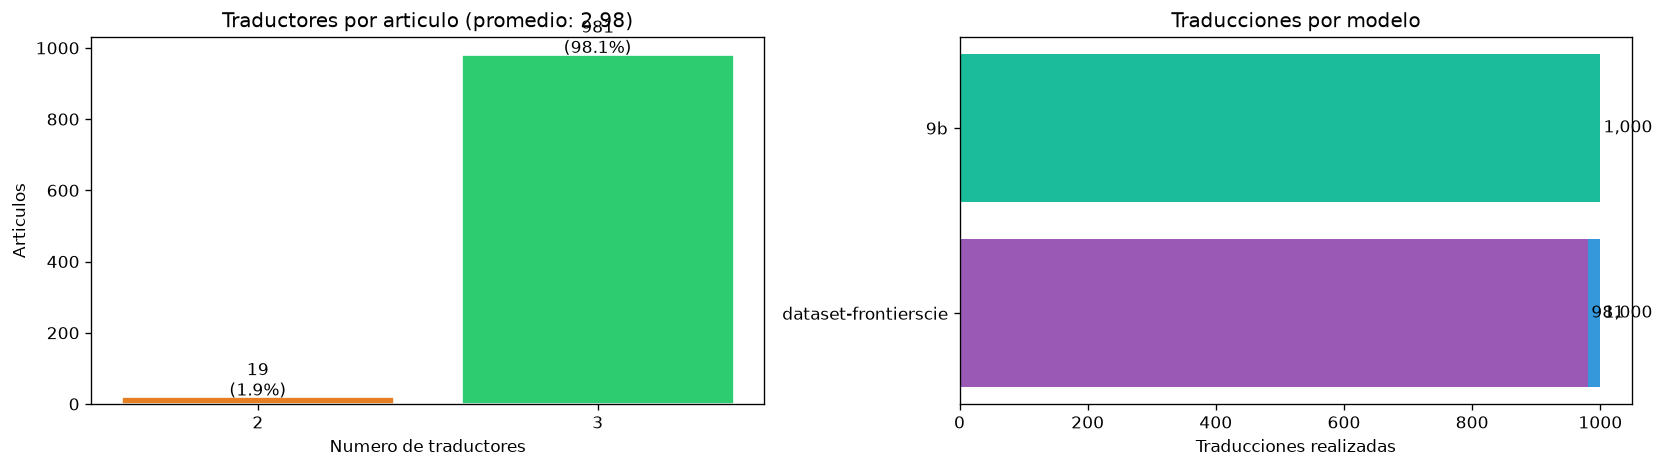

In [4]:
# Mean number of translators per article
cands_per_art = [len(p.get("candidates", [])) for p in pipeline]
avg_cands = sum(cands_per_art) / len(cands_per_art)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Distribution of candidates per article
ax = axes[0]
cand_counts = Counter(cands_per_art)
labels = sorted(cand_counts.keys())
values = [cand_counts[l] for l in labels]
colors = ["#2ecc71" if l == 3 else "#e67e22" if l == 2 else "#e74c3c" for l in labels]
ax.bar(labels, values, color=colors, edgecolor="white")
ax.set_xlabel("Numero de traductores")
ax.set_ylabel("Articulos")
ax.set_title(f"Traductores por articulo (promedio: {avg_cands:.2f})")
for l, v in zip(labels, values):
    ax.text(l, v + 5, f"{v}\n({v/n_total*100:.1f}%)", ha="center", fontsize=10)
ax.set_xticks(labels)

# Share of each translator model
ax = axes[1]
short_names = [m.split(":")[-1][:20] for m in translator_models.keys()]
counts = list(translator_models.values())
bars = ax.barh(short_names, counts, color=["#3498db", "#9b59b6", "#1abc9c"])
ax.set_xlabel("Traducciones realizadas")
ax.set_title("Traducciones por modelo")
for bar, count in zip(bars, counts):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f"{count:,}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

## 3. Volume and Coverage

In [5]:
# Compute the characters of the original and the translated text
data_rows = []
for i, (art, pip) in enumerate(zip(articles, pipeline)):
    en_text = art.get("english", {}).get("text", "")
    es_text = art.get("spanish", {}).get("text", "")
    ev = pip.get("evaluation") or {}
    tu = pip.get("token_usage", {})
    cost = tu.get("cost_usd", {}).get("total_usd", 0) if tu else 0
    
    en_words = len(en_text.split()) if en_text else 0
    es_words = len(es_text.split()) if es_text else 0
    en_chars = len(en_text) if en_text else 0
    es_chars = len(es_text) if es_text else 0
    
    n_cands = len(pip.get("candidates", []))
    has_review = pip.get("review") is not None
    has_eval = pip.get("evaluation") is not None
    
    classification = art.get("english", {}).get("classification", "unknown")
    
    data_rows.append({
        "id": i + 1,
        "en_words": en_words,
        "es_words": es_words,
        "en_chars": en_chars,
        "es_chars": es_chars,
        "n_candidates": n_cands,
        "has_review": has_review,
        "has_eval": has_eval,
        "char_ratio": ev.get("char_ratio", 0),
        "overall_score": ev.get("overall_score", None),
        "clarity": ev.get("clarity", None),
        "fidelity": ev.get("fidelity", None),
        "completeness": ev.get("completeness", None),
        "fluency": ev.get("fluency", None),
        "cost_usd": cost,
        "classification": classification,
    })

df = pd.DataFrame(data_rows)

print("TRANSLATION VOLUME")
print("=" * 65)
print(f"Original words (EN):        {df['en_words'].sum():>12,}")
print(f"Translated words (ES):      {df['es_words'].sum():>12,}")
print(f"Original characters (EN):   {df['en_chars'].sum():>12,}")
print(f"Translated characters (ES): {df['es_chars'].sum():>12,}")
print(f"Word ratio ES/EN:           {df['es_words'].sum()/df['en_words'].sum():>12.3f}")
print(f"Char ratio ES/EN:           {df['es_chars'].sum()/df['en_chars'].sum():>12.3f}")
print()

# Topic classification
cls_counts = df["classification"].value_counts()
print("TOPIC CLASSIFICATION (generated by the pipeline)")
print("-" * 50)
for cls, cnt in cls_counts.head(15).items():
    print(f"  {cls:<30} {cnt:>4} ({cnt/n_total*100:.1f}%)")

TRANSLATION VOLUME
Original words (EN):           3,268,319
Translated words (ES):         3,015,787
Original characters (EN):     17,634,690
Translated characters (ES):   18,433,116
Word ratio ES/EN:                  0.923
Char ratio ES/EN:                  1.045

TOPIC CLASSIFICATION (generated by the pipeline)
--------------------------------------------------
  history                         284 (28.4%)
  entertainment                   260 (26.0%)
  biography                       106 (10.6%)
  science                         101 (10.1%)
  sports                           96 (9.6%)
  video game                       45 (4.5%)
  technology                       23 (2.3%)
  politics                         18 (1.8%)
  medicine                         12 (1.2%)
  literature                       10 (1.0%)
  novel                             9 (0.9%)
  other                             9 (0.9%)
  Science                           6 (0.6%)
  education                         3 (0.3%)


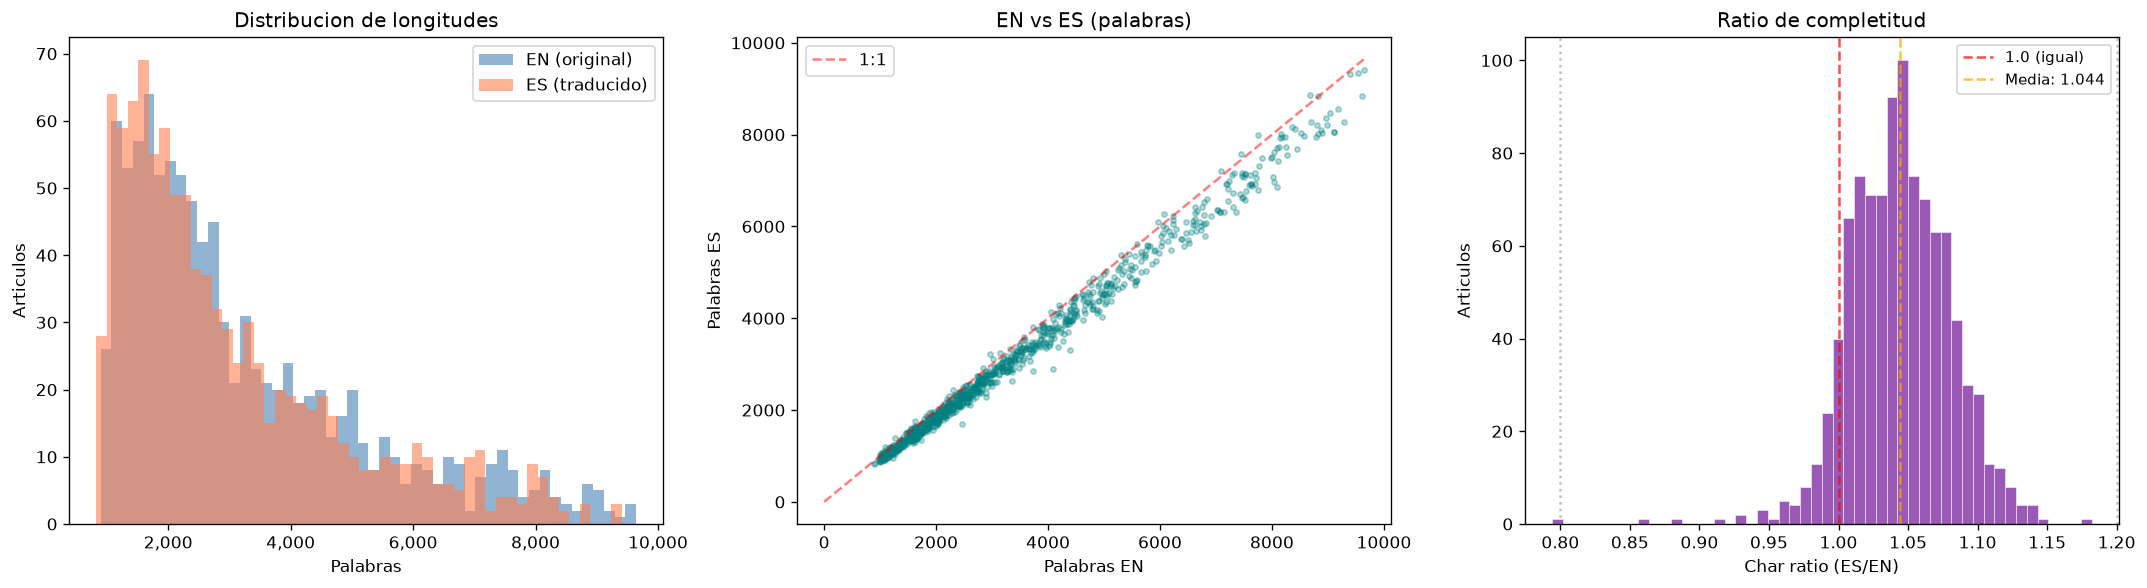

Char ratio: mean=1.044, median=1.044, min=0.794, max=1.182
Truncated (<0.8):  1
Possibly truncated (<0.9): 3
Expanded (>1.1):  56


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution of original vs translated words
ax = axes[0]
ax.hist(df["en_words"], bins=50, alpha=0.6, label="EN (original)", color="steelblue")
ax.hist(df["es_words"], bins=50, alpha=0.6, label="ES (traducido)", color="coral")
ax.set_xlabel("Palabras")
ax.set_ylabel("Articulos")
ax.set_title("Distribucion de longitudes")
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Scatter: EN words vs ES words
ax = axes[1]
ax.scatter(df["en_words"], df["es_words"], alpha=0.3, s=10, color="teal")
max_w = max(df["en_words"].max(), df["es_words"].max())
ax.plot([0, max_w], [0, max_w], "r--", alpha=0.5, label="1:1")
ax.set_xlabel("Palabras EN")
ax.set_ylabel("Palabras ES")
ax.set_title("EN vs ES (palabras)")
ax.legend()

# Char ratio distribution
ax = axes[2]
ratios = df[df["char_ratio"] > 0]["char_ratio"]
ax.hist(ratios, bins=50, color="#9b59b6", edgecolor="white", linewidth=0.3)
ax.axvline(1.0, color="red", linestyle="--", alpha=0.7, label="1.0 (igual)")
ax.axvline(ratios.mean(), color="orange", linestyle="--", alpha=0.7, label=f"Media: {ratios.mean():.3f}")
ax.axvline(0.8, color="gray", linestyle=":", alpha=0.5)
ax.axvline(1.2, color="gray", linestyle=":", alpha=0.5)
ax.set_xlabel("Char ratio (ES/EN)")
ax.set_ylabel("Articulos")
ax.set_title("Ratio de completitud")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Stats
print(f"Char ratio: mean={ratios.mean():.3f}, median={ratios.median():.3f}, "
      f"min={ratios.min():.3f}, max={ratios.max():.3f}")
print(f"Truncated (<0.8):  {(ratios < 0.8).sum()}")
print(f"Possibly truncated (<0.9): {(ratios < 0.9).sum()}")
print(f"Expanded (>1.1):  {(ratios > 1.1).sum()}")

## 4. Quality (Evaluation Scores)

In [7]:
df_eval = df[df["has_eval"]].copy()
metrics = ["clarity", "fidelity", "completeness", "fluency", "overall_score"]

print("QUALITY METRICS")
print("=" * 75)
print(f"Articles evaluated: {len(df_eval)} / {n_total}")
print()
print(f"{'Metric':<16} {'Mean':>7} {'Median':>8} {'Min':>5} {'Max':>5} {'Std':>6} {'<90':>5} {'<80':>5}")
print("-" * 75)
for m in metrics:
    vals = df_eval[m].dropna()
    below_90 = (vals < 90).sum()
    below_80 = (vals < 80).sum()
    print(f"{m:<16} {vals.mean():>7.1f} {vals.median():>8.0f} {vals.min():>5.0f} {vals.max():>5.0f} "
          f"{vals.std():>6.1f} {below_90:>5} {below_80:>5}")

QUALITY METRICS
Articles evaluated: 995 / 1000

Metric              Mean   Median   Min   Max    Std   <90   <80
---------------------------------------------------------------------------
clarity             97.7       98    90    98    1.0     0     0
fidelity            97.6       98    70    99    1.3     2     1
completeness        99.8      100    70   100    1.6     3     2
fluency             97.5       98    92    99    1.0     0     0
overall_score       95.9       96    70    98    2.0     5     1


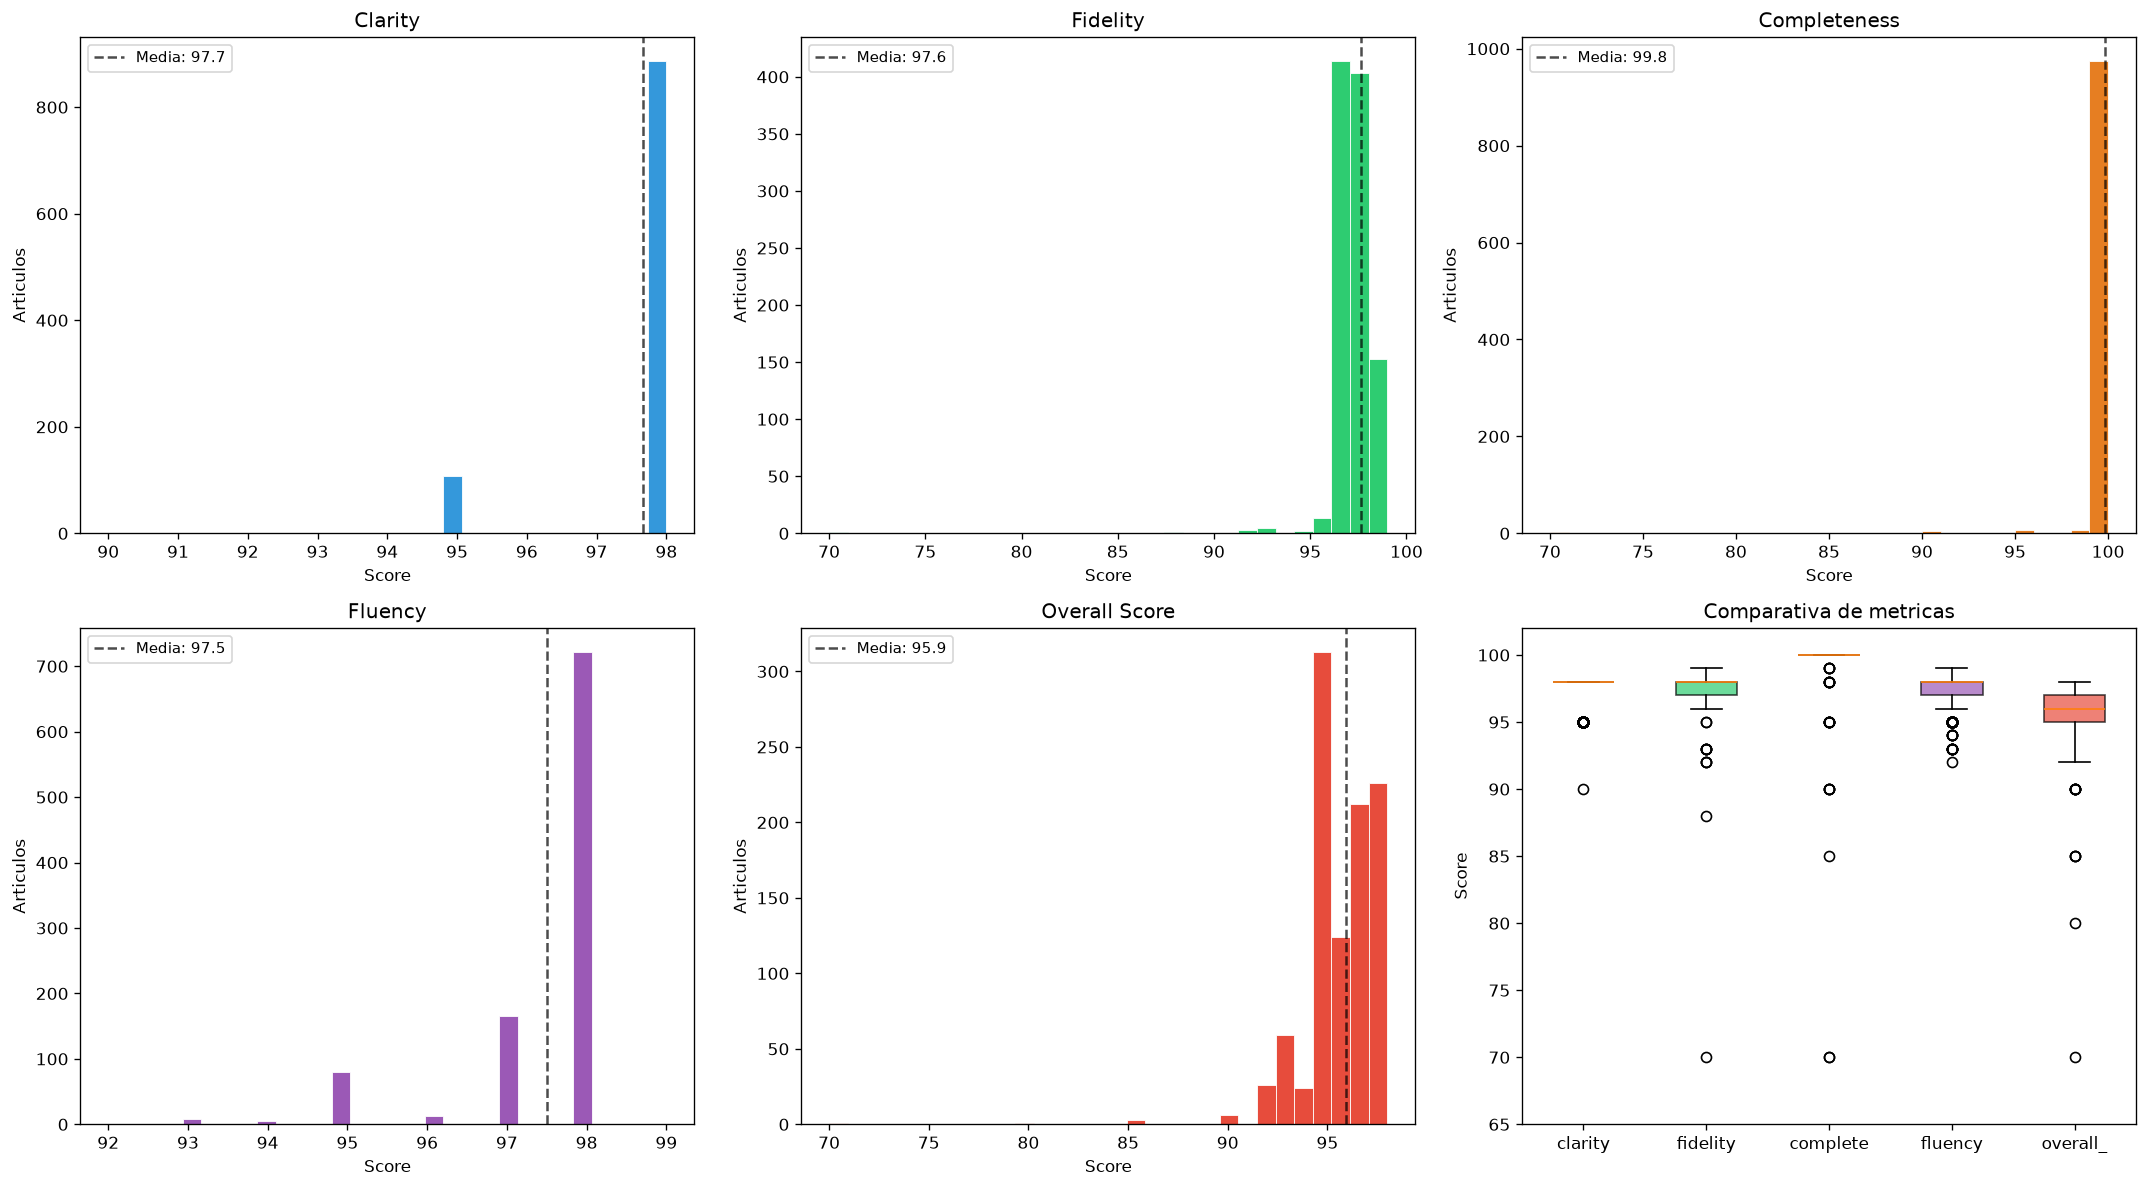

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

colors = ["#3498db", "#2ecc71", "#e67e22", "#9b59b6", "#e74c3c"]

for i, m in enumerate(metrics):
    ax = axes[i]
    vals = df_eval[m].dropna()
    ax.hist(vals, bins=30, color=colors[i], edgecolor="white", linewidth=0.5)
    ax.axvline(vals.mean(), color="black", linestyle="--", alpha=0.7,
               label=f"Media: {vals.mean():.1f}")
    ax.set_xlabel("Score")
    ax.set_ylabel("Articulos")
    ax.set_title(m.replace("_", " ").title())
    ax.legend(fontsize=9)

# Comparative box plot in the last panel
ax = axes[5]
bp_data = [df_eval[m].dropna().values for m in metrics]
bp = ax.boxplot(bp_data, patch_artist=True)
ax.set_xticks(range(1, len(metrics) + 1))
ax.set_xticklabels([m[:8] for m in metrics])
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel("Score")
ax.set_title("Comparativa de metricas")
ax.set_ylim(65, 102)

plt.tight_layout()
plt.show()

In [9]:
# Distribution of overall_score by range
bins = [0, 70, 80, 85, 90, 95, 101]
labels = ["<70", "70-79", "80-84", "85-89", "90-94", "95-100"]
df_eval["score_bin"] = pd.cut(df_eval["overall_score"], bins=bins, labels=labels, right=False)

score_dist = df_eval["score_bin"].value_counts().sort_index()
print("OVERALL SCORE DISTRIBUTION")
print("-" * 50)
for label, count in score_dist.items():
    bar = "#" * (count // 5)
    pct = count / len(df_eval) * 100
    print(f"  {label:>7}: {count:>4} ({pct:>5.1f}%)  {bar}")

# Articles with a low score (< 90)
low_score = df_eval[df_eval["overall_score"] < 90].sort_values("overall_score")
print(f"\nArticles with score < 90: {len(low_score)}")
if len(low_score) > 0:
    print(f"{'ID':>4} {'Score':>6} {'Clarity':>8} {'Fidelity':>9} {'Compl.':>7} {'Fluency':>8} {'CharRatio':>10}")
    for _, row in low_score.iterrows():
        print(f"{row['id']:>4} {row['overall_score']:>6.0f} {row['clarity']:>8.0f} {row['fidelity']:>9.0f} "
              f"{row['completeness']:>7.0f} {row['fluency']:>8.0f} {row['char_ratio']:>10.3f}")

OVERALL SCORE DISTRIBUTION
--------------------------------------------------
      <70:    0 (  0.0%)  
    70-79:    1 (  0.1%)  
    80-84:    1 (  0.1%)  
    85-89:    3 (  0.3%)  
    90-94:  115 ( 11.6%)  #######################
   95-100:  875 ( 87.9%)  ###############################################################################################################################################################################

Articles with score < 90: 5
  ID  Score  Clarity  Fidelity  Compl.  Fluency  CharRatio
 226     70       95        70      70       95      0.972
 766     80       90        88      70       92      0.794
 385     85       98        98     100       97      0.988
 293     85       98        92      95       97      0.998
 558     85       98        97      85       98      1.071


## 5. Problems and Failures

In [10]:
print("PROBLEM SUMMARY")
print("=" * 70)

# 1. Mistral failures
mistral_missing = sum(
    1 for p in pipeline
    if not any("mistral" in c.get("model", "") for c in p.get("candidates", []))
)
print(f"\n1. MISTRAL LARGE — translation failures")
print(f"   Articles without a Mistral candidate: {mistral_missing} ({mistral_missing/n_total*100:.1f}%)")
print(f"   Cause: Azure content filtering (HTTP 400) on articles with")
print(f"   historical or war content, and systematic non-translation failures.")

# 2. Review failures
no_review = [i for i, p in enumerate(pipeline) if p.get("review") is None]
print(f"\n2. REVIEW (Stage 2) — failures")
print(f"   Articles without review: {len(no_review)} ({len(no_review)/n_total*100:.1f}%)")
print(f"   IDs: {[i+1 for i in no_review]}")
print(f"   Cause: Azure content filtering or a timeout when merging sections.")
print(f"   Impact: fell back to candidates[0] without consensus review.")

# 3. Evaluation failures
no_eval = [i for i, p in enumerate(pipeline) if p.get("evaluation") is None]
print(f"\n3. EVALUATION (Stage 3) — failures")
print(f"   Articles without evaluation: {len(no_eval)} ({len(no_eval)/n_total*100:.1f}%)")
print(f"   IDs: {[i+1 for i in no_eval]}")

# 4. Non-translation issue (candidates returned in English)
print(f"\n4. UNTRANSLATED CANDIDATES (returned in English)")
print(f"   According to errores.md, in the first 388 articles:")
print(f"   - Mistral Large: 183 arts (47.2%) returned English text")
print(f"   - GPT-4.1 mini:  47 arts (12.1%) returned English text")
print(f"   - Qwen 3.5 9B:    0 arts  (0%)   always translated correctly")
print(f"   Impact: the reviewer had fewer real candidates to merge.")
print(f"   No article was left untranslated (Qwen always worked).")

# 5. Articles with both issues
both_failed = set(no_review) & set(no_eval)
print(f"\n5. ARTICLES WITH SEVERAL FAILURES")
print(f"   No review and no evaluation: {len(both_failed)}")
if both_failed:
    print(f"   IDs: {sorted([i+1 for i in both_failed])}")

PROBLEM SUMMARY

1. MISTRAL LARGE — translation failures
   Articles without a Mistral candidate: 19 (1.9%)
   Cause: Azure content filtering (HTTP 400) on articles with
   historical or war content, and systematic non-translation failures.

2. REVIEW (Stage 2) — failures
   Articles without review: 7 (0.7%)
   IDs: [301, 385, 481, 494, 548, 649, 817]
   Cause: Azure content filtering or a timeout when merging sections.
   Impact: fell back to candidates[0] without consensus review.

3. EVALUATION (Stage 3) — failures
   Articles without evaluation: 5 (0.5%)
   IDs: [53, 301, 467, 787, 873]

4. UNTRANSLATED CANDIDATES (returned in English)
   According to errores.md, in the first 388 articles:
   - Mistral Large: 183 arts (47.2%) returned English text
   - GPT-4.1 mini:  47 arts (12.1%) returned English text
   - Qwen 3.5 9B:    0 arts  (0%)   always translated correctly
   Impact: the reviewer had fewer real candidates to merge.
   No article was left untranslated (Qwen always worked)

In [11]:
# Details of the failed articles
print("DETAILS OF ARTICLES WITH FAILURES")
print("=" * 90)
print(f"{'Art':>4} {'Cands':>5} {'Review':>7} {'Eval':>5} {'Score':>6} {'Cost':>8} {'Hint (first chars)'}")
print("-" * 90)

failed_ids = set(no_review) | set(no_eval)
for idx in sorted(failed_ids):
    p = pipeline[idx]
    cands = p.get("candidates", [])
    rev = p.get("review")
    ev = p.get("evaluation")
    tu = p.get("token_usage", {})
    cost = tu.get("cost_usd", {}).get("total_usd", 0) if tu else 0
    score = ev["overall_score"] if ev else "-"
    
    hint = ""
    if cands:
        txt = cands[0].get("text", "")[:60]
        hint = txt.split("\n")[0][:55]
    
    rev_str = "OK" if rev else "FAIL"
    eval_str = "OK" if ev else "FAIL"
    
    print(f"{idx+1:>4} {len(cands):>5} {rev_str:>7} {eval_str:>5} {str(score):>6} ${cost:>7.3f} {hint}")

DETAILS OF ARTICLES WITH FAILURES
 Art Cands  Review  Eval  Score     Cost Hint (first chars)
------------------------------------------------------------------------------------------
  53     3      OK  FAIL      - $  0.237 = Transformador =
 301     2    FAIL  FAIL      - $  0.023 Aborto forzado de Feng Jianmei
 385     2    FAIL    OK     85 $  0.091 = Abd al-Rahman ibn Muhammad ibn al-Ash'ath =
 467     3      OK  FAIL      - $  0.105 = Mindaugas =
 481     3    FAIL    OK     96 $  0.011 Controversia por el arresto de Faeq al-Mir
 494     3    FAIL    OK     97 $  0.154 Colin James Farrell (nacido el 31 de mayo de 1976) es u
 548     2    FAIL    OK     95 $  0.014 = Tío David =
 649     2    FAIL    OK     98 $  0.061 Antonio Ezequiel Cárdenas Guillén (5 de marzo de 1962 –
 787     3      OK  FAIL      - $  0.133 Oscar Palmer Robertson (nacido el 24 de noviembre de 19
 817     2    FAIL    OK     95 $  0.098 = Kylie Platt =
 873     3      OK  FAIL      - $  0.089 Secret of Ever

## 6. Execution Times

In [12]:
# Extract the timestamps
art_times = []
for i, p in enumerate(pipeline):
    ts = []
    for c in p.get("candidates", []):
        t = c.get("translated_at")
        if t: ts.append(t)
    rev = p.get("review")
    if rev:
        t = rev.get("reviewed_at")
        if t: ts.append(t)
    ev = p.get("evaluation")
    if ev:
        t = ev.get("evaluated_at")
        if t: ts.append(t)
    if ts:
        ts.sort()
        art_times.append({"id": i + 1, "first": ts[0], "last": ts[-1]})

if art_times:
    fmt = "%Y-%m-%dT%H:%M:%S.%f"
    t_start = datetime.strptime(art_times[0]["first"][:26], fmt)
    t_end = datetime.strptime(art_times[-1]["last"][:26], fmt)
    total_delta = t_end - t_start
    total_hours = total_delta.total_seconds() / 3600
    
    # Per-article durations
    durations = []
    for at in art_times:
        try:
            t0 = datetime.strptime(at["first"][:26], fmt)
            t1 = datetime.strptime(at["last"][:26], fmt)
            durations.append((t1 - t0).total_seconds())
        except:
            pass
    
    print("EXECUTION TIMES")
    print("=" * 65)
    print(f"Start:          {t_start.strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"End:            {t_end.strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"Total duration: {total_delta} ({total_hours:.1f} hours)")
    print(f"Mean/article:   {total_delta.total_seconds()/n_total:.0f} sec ({total_delta.total_seconds()/n_total/60:.1f} min)")
    print()
    
    if durations:
        dur = np.array(durations)
        print(f"Duration per article (processing):")
        print(f"  Mean:    {dur.mean():.0f} sec ({dur.mean()/60:.1f} min)")
        print(f"  Median:  {np.median(dur):.0f} sec ({np.median(dur)/60:.1f} min)")
        print(f"  Min:     {dur.min():.0f} sec")
        print(f"  Max:     {dur.max():.0f} sec ({dur.max()/60:.1f} min)")
        print(f"  P95:     {np.percentile(dur, 95):.0f} sec ({np.percentile(dur, 95)/60:.1f} min)")

EXECUTION TIMES
Start:          2026-06-15 23:10:22
End:            2026-06-20 23:58:32
Total duration: 5 days, 0:48:09.954077 (120.8 hours)
Mean/article:   435 sec (7.2 min)

Duration per article (processing):
  Mean:    281 sec (4.7 min)
  Median:  226 sec (3.8 min)
  Min:     67 sec
  Max:     1945 sec (32.4 min)
  P95:     658 sec (11.0 min)


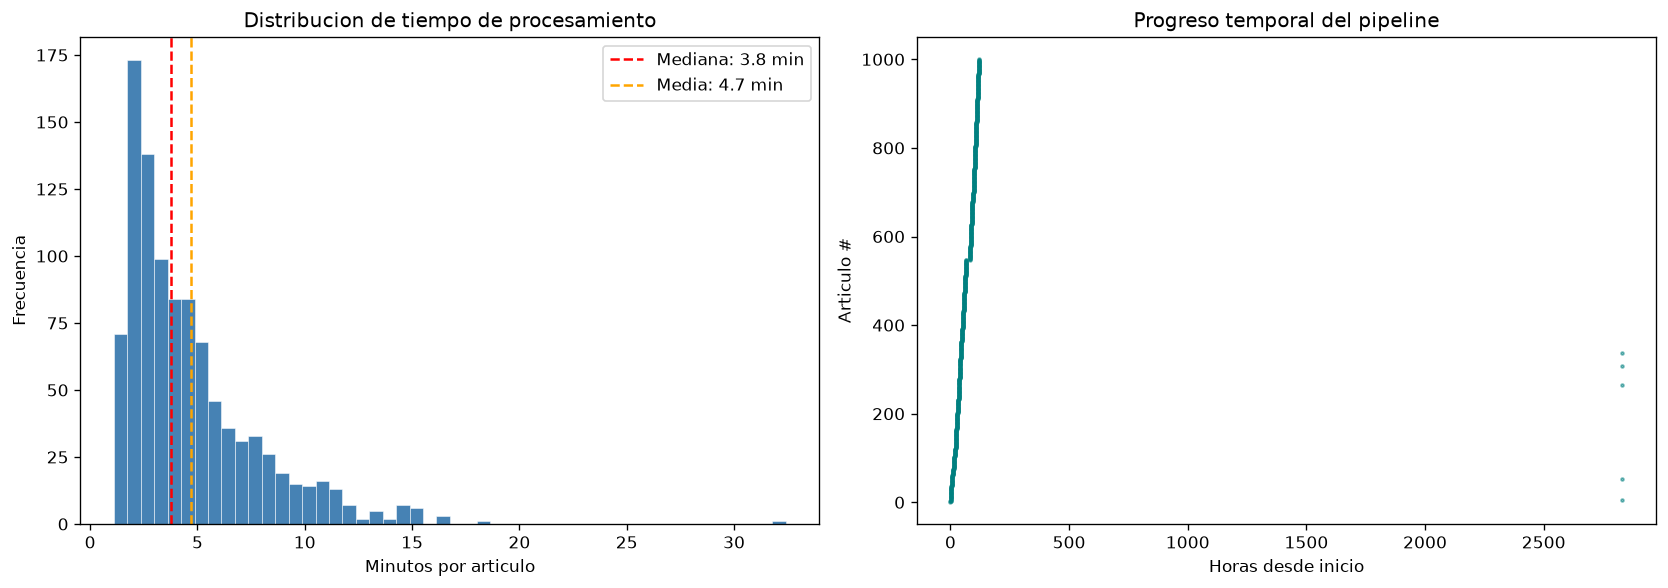

In [13]:
if durations:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Histogram of the duration per article
    ax = axes[0]
    dur_min = np.array(durations) / 60
    ax.hist(dur_min, bins=50, color="steelblue", edgecolor="white", linewidth=0.3)
    ax.axvline(np.median(dur_min), color="red", linestyle="--",
               label=f"Mediana: {np.median(dur_min):.1f} min")
    ax.axvline(np.mean(dur_min), color="orange", linestyle="--",
               label=f"Media: {np.mean(dur_min):.1f} min")
    ax.set_xlabel("Minutos por articulo")
    ax.set_ylabel("Frecuencia")
    ax.set_title("Distribucion de tiempo de procesamiento")
    ax.legend()
    
    # Timeline: article vs timestamp
    ax = axes[1]
    times_parsed = []
    for at in art_times:
        try:
            t = datetime.strptime(at["last"][:26], fmt)
            hours_from_start = (t - t_start).total_seconds() / 3600
            times_parsed.append((at["id"], hours_from_start))
        except:
            pass
    if times_parsed:
        ids, hrs = zip(*times_parsed)
        ax.scatter(hrs, ids, s=3, alpha=0.5, color="teal")
        ax.set_xlabel("Horas desde inicio")
        ax.set_ylabel("Articulo #")
        ax.set_title("Progreso temporal del pipeline")
    
    plt.tight_layout()
    plt.show()

## 7. Costs

In [14]:
cost_breakdown = summary["total_cost_usd"]

print("COST BREAKDOWN")
print("=" * 65)

# Stage 1
s1 = cost_breakdown["stage_1_translation"]
s1_total = sum(v for v in s1.values())
print(f"\nStage 1 — Translation (3 models):          ${s1_total:>8.2f} ({s1_total/total_cost*100:.1f}%)")
for model, cost in s1.items():
    short = model.split(":")[-1]
    print(f"  {short:<42} ${cost:>8.2f}")

# Stage 2
s2 = cost_breakdown["stage_2_review"]
print(f"\nStage 2 — Review (GPT-4.1):                ${s2:>8.2f} ({s2/total_cost*100:.1f}%)")

# Stage 3
s3 = cost_breakdown["stage_3_evaluation"]
print(f"Stage 3 — Evaluation (GPT-4.1 mini):        ${s3:>8.2f} ({s3/total_cost*100:.1f}%)")

# Metadata
sm = cost_breakdown["metadata"]
print(f"Metadata (title, keywords, classification):  ${sm:>8.2f} ({sm/total_cost*100:.1f}%)")

print(f"\n{'TOTAL':>47} ${total_cost:>8.2f}")
print(f"{'Cost per article':>47} ${total_cost/n_total:>8.4f}")

COST BREAKDOWN

Stage 1 — Translation (3 models):          $   20.00 (19.1%)
  dataset-frontierscience-gpt41mini          $    9.01
  dataset-frontierscience-mistral-large      $   10.98
  9b                                         $    0.00

Stage 2 — Review (GPT-4.1):                $   76.87 (73.5%)
Stage 3 — Evaluation (GPT-4.1 mini):        $    3.76 (3.6%)
Metadata (title, keywords, classification):  $    3.91 (3.7%)

                                          TOTAL $  104.54
                               Cost per article $  0.1045


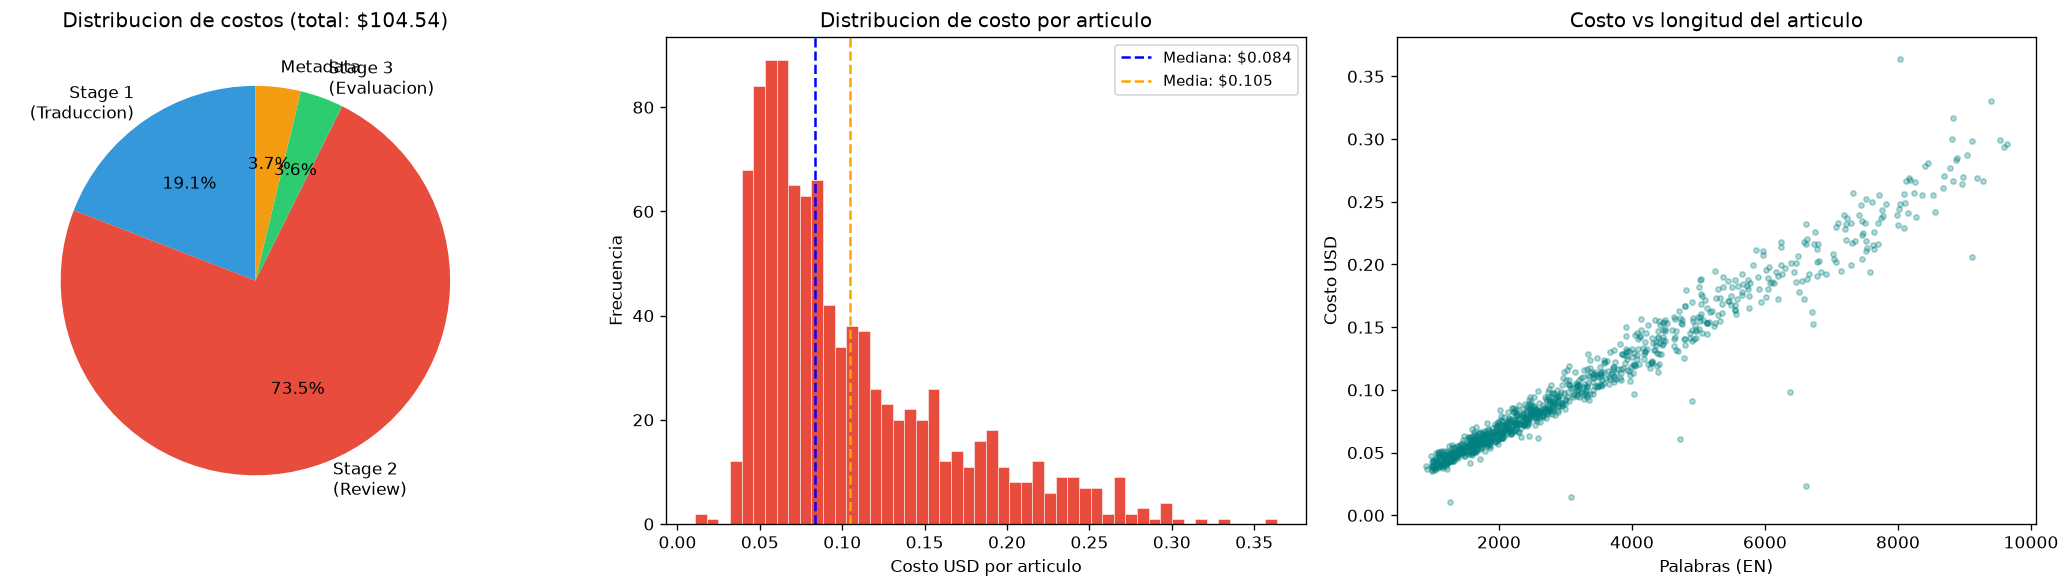


COST PERCENTILES PER ARTICLE
----------------------------------------
  P 5: $0.0432
  P10: $0.0479
  P25: $0.0599
  P50: $0.0837
  P75: $0.1331
  P90: $0.1945
  P95: $0.2333
  P99: $0.2836


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pie chart of the cost per stage
ax = axes[0]
stage_labels = ["Stage 1\n(Traduccion)", "Stage 2\n(Review)", "Stage 3\n(Evaluacion)", "Metadata"]
stage_costs = [s1_total, s2, s3, sm]
stage_colors = ["#3498db", "#e74c3c", "#2ecc71", "#f39c12"]
wedges, texts, autotexts = ax.pie(
    stage_costs, labels=stage_labels, autopct="%1.1f%%",
    colors=stage_colors, startangle=90
)
ax.set_title(f"Distribucion de costos (total: ${total_cost:.2f})")

# Histogram of the cost per article
ax = axes[1]
ax.hist(df["cost_usd"], bins=50, color="#e74c3c", edgecolor="white", linewidth=0.3)
ax.axvline(df["cost_usd"].median(), color="blue", linestyle="--",
           label=f"Mediana: ${df['cost_usd'].median():.3f}")
ax.axvline(df["cost_usd"].mean(), color="orange", linestyle="--",
           label=f"Media: ${df['cost_usd'].mean():.3f}")
ax.set_xlabel("Costo USD por articulo")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribucion de costo por articulo")
ax.legend(fontsize=9)

# Cost vs words
ax = axes[2]
ax.scatter(df["en_words"], df["cost_usd"], alpha=0.3, s=10, color="teal")
ax.set_xlabel("Palabras (EN)")
ax.set_ylabel("Costo USD")
ax.set_title("Costo vs longitud del articulo")

plt.tight_layout()
plt.show()

# Cost percentiles
print("\nCOST PERCENTILES PER ARTICLE")
print("-" * 40)
for p in [5, 10, 25, 50, 75, 90, 95, 99]:
    val = df["cost_usd"].quantile(p / 100)
    print(f"  P{p:>2}: ${val:.4f}")

In [16]:
# Total tokens
tok = summary["total_tokens"]
print("TOKEN USAGE")
print("=" * 50)
print(f"Prompt tokens:      {tok['prompt_tokens']:>14,}")
print(f"Completion tokens:  {tok['completion_tokens']:>14,}")
print(f"Total tokens:       {tok['total_tokens']:>14,}")
print(f"Ratio output/input: {tok['completion_tokens']/tok['prompt_tokens']:.2f}")
print(f"\nTokens per article (mean): {tok['total_tokens']/n_total:,.0f}")
print(f"Cost per million tokens:   ${total_cost / (tok['total_tokens']/1_000_000):.2f}")

TOKEN USAGE
Prompt tokens:          51,018,864
Completion tokens:      19,899,037
Total tokens:           70,917,901
Ratio output/input: 0.39

Tokens per article (mean): 70,918
Cost per million tokens:   $1.47


## 8. Comparison with the Earlier Test Run

In [17]:
# Load test run (62 articles = test.raw) for comparison
test_pipe_file = Path("../output/wikitext/tests/wikitext-103-raw.wiki.test_pipeline_260612_032122.json")
if test_pipe_file.exists():
    with open(test_pipe_file, encoding="utf-8") as f:
        test_data = json.load(f)
    test_pipeline = test_data.get("pipeline", [])
    test_summary = test_data.get("summary", {})
    
    test_scores = [p["evaluation"]["overall_score"] 
                   for p in test_pipeline if p.get("evaluation")]
    test_cost = test_summary.get("total_cost_usd", {}).get("total", 0)
    test_tokens = test_summary.get("total_tokens", {}).get("total_tokens", 0)
    test_n = len(test_pipeline)
    
    print("COMPARISON: TEST RUN (62 arts) vs PRODUCTION (1000 arts)")
    print("=" * 70)
    print(f"{'Metric':<30} {'Test (62)':>15} {'Prod (1000)':>15} {'Delta':>10}")
    print("-" * 70)
    
    test_avg = sum(test_scores)/len(test_scores) if test_scores else 0
    prod_avg = sum(scores_all)/len(scores_all) if scores_all else 0
    print(f"{'Mean score':<30} {test_avg:>15.1f} {prod_avg:>15.1f} {prod_avg-test_avg:>+10.1f}")
    
    test_cpp = test_cost/test_n if test_n else 0
    prod_cpp = total_cost/n_total
    print(f"{'Cost/article (USD)':<30} ${test_cpp:>14.4f} ${prod_cpp:>14.4f} ${prod_cpp-test_cpp:>+9.4f}")
    
    test_tpa = test_tokens/test_n if test_n else 0
    prod_tpa = total_tokens/n_total
    print(f"{'Tokens/article':<30} {test_tpa:>15,.0f} {prod_tpa:>15,.0f} {prod_tpa-test_tpa:>+10,.0f}")
    
    print(f"{'Total cost (USD)':<30} ${test_cost:>14.2f} ${total_cost:>14.2f}")
    print(f"{'Total tokens':<30} {test_tokens:>15,} {total_tokens:>15,}")
else:
    print("Test run file not found, so there is nothing to compare.")

COMPARISON: TEST RUN (62 arts) vs PRODUCTION (1000 arts)
Metric                               Test (62)     Prod (1000)      Delta
----------------------------------------------------------------------
Mean score                                96.0            95.9       -0.0
Cost/article (USD)             $        0.1183 $        0.1045 $  -0.0138
Tokens/article                          79,442          70,918     -8,525
Total cost (USD)               $          7.34 $        104.54
Total tokens                         4,925,434      70,917,901


## 9. Quality by Topic Classification

In [18]:
# Mean score per classification
df_with_score = df[df["overall_score"].notna()].copy()
cls_stats = df_with_score.groupby("classification").agg(
    n=("id", "count"),
    score_avg=("overall_score", "mean"),
    score_min=("overall_score", "min"),
    cost_avg=("cost_usd", "mean"),
    cost_total=("cost_usd", "sum"),
).sort_values("n", ascending=False)

print("QUALITY AND COST BY TOPIC")
print("=" * 80)
print(f"{'Topic':<25} {'N':>4} {'Score avg':>10} {'Score min':>10} {'$/art':>8} {'$ total':>9}")
print("-" * 80)
for tema, row in cls_stats.head(15).iterrows():
    print(f"{tema[:25]:<25} {row['n']:>4} {row['score_avg']:>10.1f} {row['score_min']:>10.0f} "
          f"${row['cost_avg']:>7.4f} ${row['cost_total']:>8.2f}")

QUALITY AND COST BY TOPIC
Topic                        N  Score avg  Score min    $/art   $ total
--------------------------------------------------------------------------------
history                   283.0       95.5         70 $ 0.1105 $   31.28
entertainment             260.0       95.8         80 $ 0.0878 $   22.83
biography                 106.0       96.1         90 $ 0.1125 $   11.92
science                   101.0       96.3         90 $ 0.1030 $   10.41
sports                    95.0       96.3         90 $ 0.1168 $   11.09
video game                44.0       96.3         93 $ 0.1031 $    4.54
technology                22.0       96.1         92 $ 0.1255 $    2.76
politics                  17.0       96.2         93 $ 0.1109 $    1.88
medicine                  12.0       97.3         95 $ 0.1457 $    1.75
literature                10.0       96.2         95 $ 0.1098 $    1.10
other                      9.0       95.7         92 $ 0.0927 $    0.83
novel                    

## 10. Conclusions and Recommendations

In [19]:
print("""
CONCLUSIONS
===========

1. COVERAGE: 1,000/1,000 articles translated (100%). Although 7 articles
   skipped the review and 5 were not evaluated, ALL of them have a Spanish
   translation thanks to the fallback to candidates[0].

2. QUALITY: mean score of 95.9/100. 88% of the articles score
   >= 95. Only 5 articles (0.5%) score < 90. Completeness is
   the highest metric (99.8 mean), which shows that the truncation
   fix worked correctly.

3. MODELS: Qwen 3.5:9b (local Ollama, $0) was the most reliable
   translator (100% success). Mistral Large failed on 19 articles
   (Azure content filtering) and did not translate ~47% of the first
   388 articles. GPT-4.1 mini did not translate 12.1% of the time.

4. COSTS: $104.54 in total. 73.5% of the cost was Stage 2 (review)
   because it uses GPT-4.1 (the most expensive model). Stage 1 (translation)
   was only 19.1% of the cost. Ollama (Qwen) gave free translations.

5. TIMES: ~120 hours (5 days) of execution. A mean of ~7 minutes
   per article, including the 3 stages + metadata.

RECOMMENDATIONS
===============

1. Replace Mistral Large: with 47% non-translations and 1.9% content
   filtering, it adds little to the consensus. Consider
   DeepSeek-V3 or a second local Ollama model.

2. Add a language check after translation: detect candidates
   returned in English before sending them to the reviewer.

3. Reduce the reviewer cost: Stage 2 dominates the cost. Check whether
   GPT-4.1 mini can do an acceptable review (it would save ~$60).

4. The 7+5 articles with partial failures could be reprocessed
   one by one to complete the review/evaluation.
""")


CONCLUSIONS

1. COVERAGE: 1,000/1,000 articles translated (100%). Although 7 articles
   skipped the review and 5 were not evaluated, ALL of them have a Spanish
   translation thanks to the fallback to candidates[0].

2. QUALITY: mean score of 95.9/100. 88% of the articles score
   >= 95. Only 5 articles (0.5%) score < 90. Completeness is
   the highest metric (99.8 mean), which shows that the truncation
   fix worked correctly.

3. MODELS: Qwen 3.5:9b (local Ollama, $0) was the most reliable
   translator (100% success). Mistral Large failed on 19 articles
   (Azure content filtering) and did not translate ~47% of the first
   388 articles. GPT-4.1 mini did not translate 12.1% of the time.

4. COSTS: $104.54 in total. 73.5% of the cost was Stage 2 (review)
   because it uses GPT-4.1 (the most expensive model). Stage 1 (translation)
   was only 19.1% of the cost. Ollama (Qwen) gave free translations.

5. TIMES: ~120 hours (5 days) of execution. A mean of ~7 minutes
   per article, inc